*  DSC550-T302 Data Mining (2265-1)
*  5.2 Exercise: Build your own Sentiment Analysis Model
*  David Jorgensen

# 5.2 Exercise: Build your own Sentiment Analysis Model

# Instructions

You will build a model with the movie reviews dataset that you worked with in Week 3: [Bag of Words Meets Bags of Popcorn](https://www.kaggle.com/c/word2vec-nlp-tutorial/data). 

1. Get the stemmed data using the same process you did in Week 3.
2. Split this into a training and test set.
3. Fit and apply the tf-idf vectorization to the training set.
4. Apply but DO NOT FIT the tf-idf vectorization to the test set (Why?).
5. Train a logistic regression using the training data.
6. Find the model accuracy on test set.
7. Create a confusion matrix for the test set predictions.
8. Get the precision, recall, and F1-score for the test set predictions.
9. Create a ROC curve for the test set.
10. Repeat steps 5 – 9 with a random forest classifier.




# Assignment

In [45]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# Load data
df = pd.read_csv('labeledTrainData.tsv', sep='\t')

# Check data is loaded properly
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         25000 non-null  object
 1   sentiment  25000 non-null  int64 
 2   review     25000 non-null  object
dtypes: int64(1), object(2)
memory usage: 586.1+ KB
None


## Step 1: Verify Stemming

In [46]:
# Remove HTML/special-character remnants
import re
df['review'] = df['review'].apply(lambda x: re.sub(r'<.*?>', '', x))
df['review'] = df['review'].apply(lambda x: re.sub(r'[^a-zA-Z\s]', '', x))
print("HTML and special characters removed.")

# Convert all text to lowercase
df['review'] = df['review'].str.lower()
print("Text converted to lowercase.")

# Remove punctuation
import string
df['review'] = df['review'].str.translate(str.maketrans('', '', string.punctuation))
print("Punctuation removed.")

# Remove stop words
print("Stopwords downloaded.")
stop_words = set(stopwords.words('english'))
df['review'] = df['review'].apply(lambda x: ' '.join([word for word in x.split() if word not in stop_words]))
print("Stop words removed.")

# Perform stemming
stemmer = PorterStemmer()
df['review'] = df['review'].apply(lambda x: ' '.join([stemmer.stem(word) for word in x.split()]))

# Print the first few rows of the dataframe after preprocessing
print(df.head())

HTML and special characters removed.
Text converted to lowercase.
Punctuation removed.
Stopwords downloaded.
Stop words removed.
       id  sentiment                                             review
0  5814_8          1  stuff go moment mj ive start listen music watc...
1  2381_9          1  classic war world timothi hine entertain film ...
2  7759_3          0  film start manag nichola bell give welcom inve...
3  3630_4          0  must assum prais film greatest film opera ever...
4  9495_8          1  superbl trashi wondrous unpretenti exploit hoo...


In [63]:
# Verify stemming by printing a few sample reviews
print('Sample stemmed reviews:')
for review in df['review'].head(3):
    print(review[:300])
    print('---')

Sample stemmed reviews:
stuff go moment mj ive start listen music watch odd documentari watch wiz watch moonwalk mayb want get certain insight guy thought realli cool eighti mayb make mind whether guilti innoc moonwalk part biographi part featur film rememb go see cinema origin releas subtl messag mj feel toward press also
---
classic war world timothi hine entertain film obvious goe great effort length faith recreat h g well classic book mr hine succe watch film appreci fact standard predict hollywood fare come everi year eg spielberg version tom cruis slightest resembl book obvious everyon look differ thing movi envis a
---
film start manag nichola bell give welcom investor robert carradin primal park secret project mutat primal anim use fossil dna like jurassik park scientist resurrect one natur fearsom predat sabretooth tiger smilodon scientif ambit turn deadli howev high voltag fenc open creatur escap begin savag st
---


## Step 2: Train/Test Split

In [48]:
X = df['review']
y = df['sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f'Training samples: {len(X_train)}')
print(f'Test samples:     {len(X_test)}')

Training samples: 20000
Test samples:     5000


## Steps 3 & 4: TF-IDF Vectorization

In [49]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Step 3: Fit AND transform on training set
tfidf = TfidfVectorizer(max_features=10000)
X_train_tfidf = tfidf.fit_transform(X_train)
print(f'Training TF-IDF shape: {X_train_tfidf.shape}')

# Step 4: Transform ONLY (do not fit) on test set
X_test_tfidf = tfidf.transform(X_test)
print(f'Test TF-IDF shape:     {X_test_tfidf.shape}')

Training TF-IDF shape: (20000, 10000)
Test TF-IDF shape:     (5000, 10000)


### Why not fit the TF-IDF on the test set?

The TF-IDF vectorizer learns a vocabulary and inverse-document-frequency (IDF) weights from the data it is fit on. Fitting on the test set would constitute data leakage: the model's input representation would incorporate statistical information from the test documents, which the model is not supposed to have seen during training. This would produce an overly optimistic evaluation that does not reflect real-world performance.

By calling `.transform()` (not `.fit_transform()`) on the test set, we apply the same vocabulary and IDF weights learned from the training set. This ensures the test data is represented in exactly the same feature space as the training data, giving an honest measure of generalization.

## Steps 5-9: Logistic Regression

In [50]:
# Step 5: Train logistic regression
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_tfidf, y_train)
print('Logistic Regression trained.')

Logistic Regression trained.


In [51]:
# Step 6: Accuracy
lr_preds = lr.predict(X_test_tfidf)
lr_acc = (lr_preds == y_test).mean()
print(f'Logistic Regression Test Accuracy: {lr_acc:.4f}')

Logistic Regression Test Accuracy: 0.8834


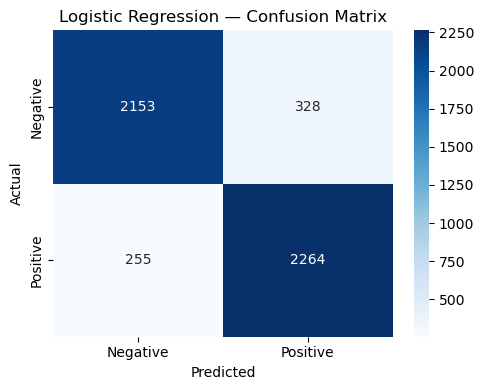

In [52]:
# Step 7: Confusion matrix
lr_cm = confusion_matrix(y_test, lr_preds)
plt.figure(figsize=(5, 4))
sns.heatmap(lr_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'])
plt.title('Logistic Regression — Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

In [53]:
# Step 8: Precision, recall, F1-score
print('Logistic Regression — Classification Report')
print(classification_report(y_test, lr_preds, target_names=['Negative', 'Positive']))

Logistic Regression — Classification Report
              precision    recall  f1-score   support

    Negative       0.89      0.87      0.88      2481
    Positive       0.87      0.90      0.89      2519

    accuracy                           0.88      5000
   macro avg       0.88      0.88      0.88      5000
weighted avg       0.88      0.88      0.88      5000



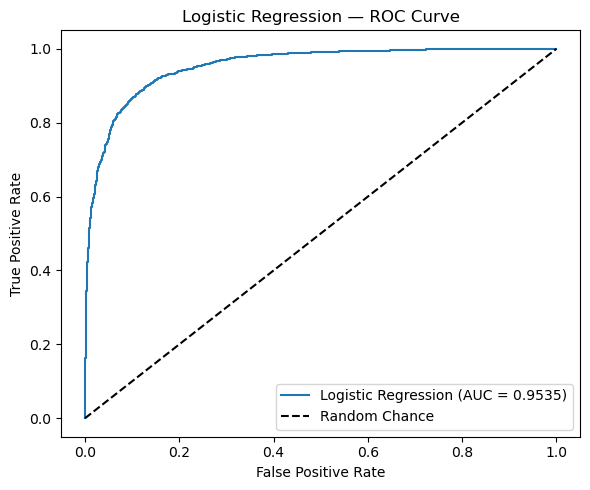

In [54]:
# Step 9: ROC curve
from sklearn.metrics import roc_curve, roc_auc_score

lr_probs = lr.predict_proba(X_test_tfidf)[:, 1]
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probs)
lr_auc = roc_auc_score(y_test, lr_probs)

plt.figure(figsize=(6, 5))
plt.plot(lr_fpr, lr_tpr, label=f'Logistic Regression (AUC = {lr_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Chance')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Logistic Regression — ROC Curve')
plt.legend()
plt.tight_layout()
plt.show()

## Steps 5–9: Random Forest

In [55]:
from sklearn.ensemble import RandomForestClassifier

# Step 5 (RF): Train random forest
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train_tfidf, y_train)
print('Random Forest trained.')

Random Forest trained.


In [56]:
# Step 6 (RF): Accuracy
rf_preds = rf.predict(X_test_tfidf)
rf_acc = (rf_preds == y_test).mean()
print(f'Random Forest Test Accuracy: {rf_acc:.4f}')

Random Forest Test Accuracy: 0.8458


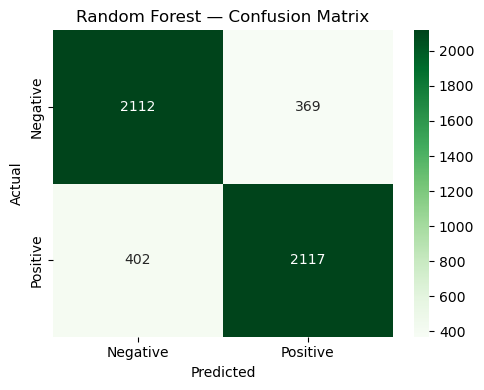

In [57]:
# Step 7 (RF): Confusion matrix
rf_cm = confusion_matrix(y_test, rf_preds)
plt.figure(figsize=(5, 4))
sns.heatmap(rf_cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'])
plt.title('Random Forest — Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

In [58]:
# Step 8 (RF): Precision, recall, F1-score
print('Random Forest — Classification Report')
print(classification_report(y_test, rf_preds, target_names=['Negative', 'Positive']))

Random Forest — Classification Report
              precision    recall  f1-score   support

    Negative       0.84      0.85      0.85      2481
    Positive       0.85      0.84      0.85      2519

    accuracy                           0.85      5000
   macro avg       0.85      0.85      0.85      5000
weighted avg       0.85      0.85      0.85      5000



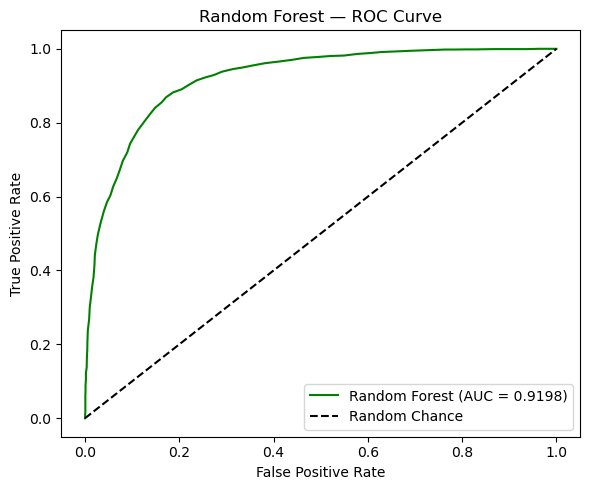

In [59]:
# Step 9 (RF): ROC curve
rf_probs = rf.predict_proba(X_test_tfidf)[:, 1]
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probs)
rf_auc = roc_auc_score(y_test, rf_probs)

plt.figure(figsize=(6, 5))
plt.plot(rf_fpr, rf_tpr, label=f'Random Forest (AUC = {rf_auc:.4f})', color='green')
plt.plot([0, 1], [0, 1], 'k--', label='Random Chance')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Random Forest — ROC Curve')
plt.legend()
plt.tight_layout()
plt.show()

## Model Comparison: Logistic Regression vs. Random Forest

In [60]:
from sklearn.metrics import precision_recall_fscore_support

# Collect metrics for both models
models = {'Logistic Regression': (lr_preds, lr_probs, lr_auc),
          'Random Forest':        (rf_preds, rf_probs, rf_auc)}

rows = []
for name, (preds, probs, auc) in models.items():
    acc = (preds == y_test).mean()
    p, r, f1, _ = precision_recall_fscore_support(y_test, preds, average='weighted')
    rows.append({'Model': name, 'Accuracy': acc, 'Precision': p,
                 'Recall': r, 'F1-Score': f1, 'AUC-ROC': auc})

comparison = pd.DataFrame(rows).set_index('Model')
print(comparison.round(4).to_string())

                     Accuracy  Precision  Recall  F1-Score  AUC-ROC
Model                                                              
Logistic Regression    0.8834     0.8837  0.8834    0.8834   0.9535
Random Forest          0.8458     0.8459  0.8458    0.8458   0.9198


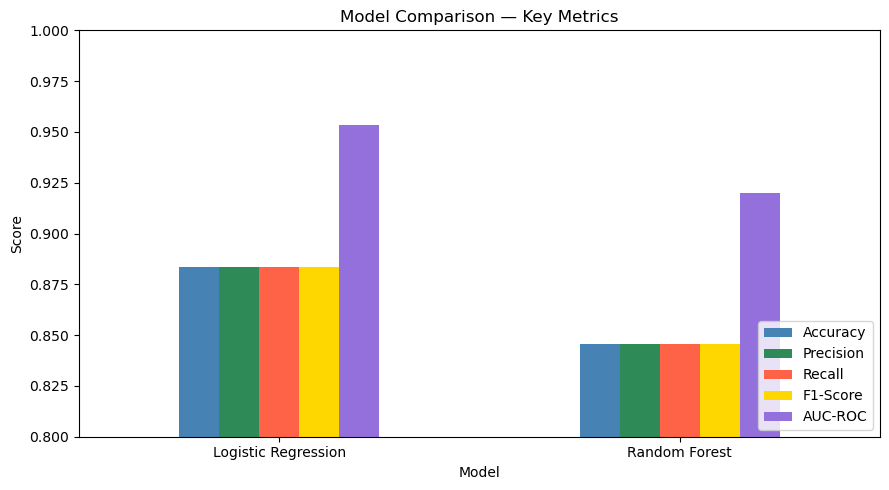

In [61]:
# Side-by-side bar chart of all metrics
comparison.plot(kind='bar', figsize=(9, 5), ylim=(0.8, 1.0), rot=0,
                color=['steelblue', 'seagreen', 'tomato', 'gold', 'mediumpurple'])
plt.title('Model Comparison — Key Metrics')
plt.ylabel('Score')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

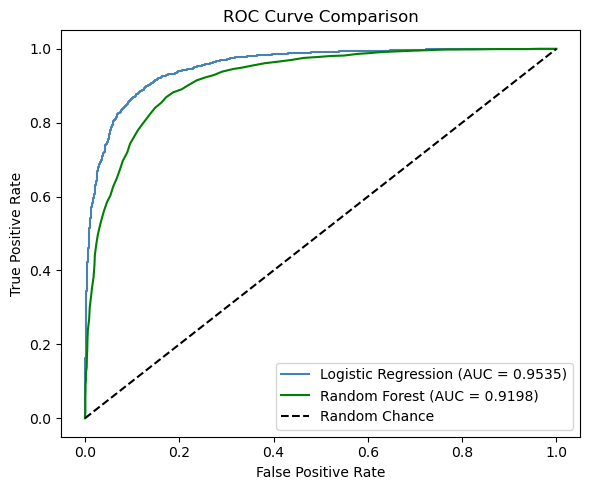

In [62]:
# Overlay ROC curves
plt.figure(figsize=(6, 5))
plt.plot(lr_fpr, lr_tpr, label=f'Logistic Regression (AUC = {lr_auc:.4f})', color='steelblue')
plt.plot(rf_fpr, rf_tpr, label=f'Random Forest (AUC = {rf_auc:.4f})', color='green')
plt.plot([0, 1], [0, 1], 'k--', label='Random Chance')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.tight_layout()
plt.show()

### Discussion

Logistic regression is the clear winner across every metric by 3-4 percentage points. A few specific things worth noting:

Precision ≈ Recall ≈ F1 for both models. The three are nearly identical within each model, which tells you the dataset is well-balanced (50/50 positive/negative) and neither model has a systematic bias toward predicting one class: the errors are roughly symmetric.

AUC is meaningfully higher than accuracy for both models. LR's 95.35% AUC vs. 88.34% accuracy means the model has strong discriminative ability across all decision thresholds, but the default 0.5 cutoff isn't capturing all of that. If you needed to tune the threshold (e.g., to prioritize catching negative reviews), there's headroom to improve recall at the cost of precision.

The AUC gap (3.4 pts) is larger than the accuracy gap (3.8 pts) in relative terms. RF's probability estimates are less calibrated than LR's: it can still rank reviews in the right order reasonably well, but it's less confident and less precise about where to draw the line. This is a property of random forests: their soft probabilities (votes averaged across trees) tend to be overconfident and cluster near 0 and 1.

**Conclusion.** Both models are performing well above chance on a hard real-world task, but logistic regression is the better choice here. It's faster to train, more interpretable (word coefficients map directly to sentiment contribution), and outperforms RF on every metric because the TF-IDF/sentiment relationship is essentially linear.